# Run23 — local city evaluation
Evaluate the frozen YOLO11s candidate from Run23 on the unchanged 190 local images. No training or threshold tuning. The dataset has prior project exposure; report this as a descriptive local comparison. Explanation precedes each step and actual results are interpreted afterward.

## 1. Freeze the Run23 candidate before local scoring
Use only the YOLO11s candidate selected on China validation. Preserve its frozen confidence, 640-pixel size, NMS IoU 0.7 and max_det 300. Also report the predeclared common confidence 0.46 used for historical Run17. No training, confidence search or model selection on local results. These 190 images have prior project exposure and are not a fresh independent holdout.

**Frozen checkpoint verified:** Run23 YOLO11s, exact SHA256 matches the selected weights. Confidence 0.001 came from RDD validation, not local labels. A very low confidence can create many false alarms; report it without optimizing on local data.

## 2. Audit the unchanged local dataset
Verify all 190 images, class order, finite label coordinates and exact duplicate hashes. Keep healthy images with empty labels. No label edits are performed.

**Audit:** 190 images, 333 boxes, 56 healthy images. Loader train/val aliases do not trigger training. Exact duplicate pixels were not found; related views can still affect independence.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## 3. Score the fixed model
mAP uses confidence 0.001 to retain the ranking. Fixed-confidence precision, recall and F1 use same-class one-to-one IoU 0.5 matching. Record healthy-road false alarms separately. Curves are descriptive only and cannot be used to choose a new local threshold.

... (4 outputs left out)

,confidence,cls,TP,FP,FN,precision,recall,F1
0,0.001,D00,54,2375,101,0.022231,0.348387,0.041796
1,0.001,D10,26,3798,65,0.006799,0.285714,0.013282
2,0.001,D20,31,2358,7,0.012976,0.815789,0.025546
3,0.001,D40,37,8209,12,0.004487,0.755102,0.008921
4,0.460,D00,3,2,152,0.600000,0.019355,0.037500
5,0.460,D10,3,3,88,0.500000,0.032967,0.061856
6,0.460,D20,8,2,30,0.800000,0.210526,0.333333
7,0.460,D40,18,6,31,0.750000,0.367347,0.493151


,cls,mAP50,mAP50_95
0,D00,0.058955,0.029020
1,D10,0.040061,0.011848
2,D20,0.468175,0.229877
3,D40,0.404135,0.219258


## 4. Descriptive comparison with the historical Run17 score
Both rows use confidence 0.46, 640 pixels and the same local snapshot. The historical reference is recorded from Run22, not retrained here. This is a post-exposure comparison, not a new independent model-selection test. No automatic replacement of Run17.

,model,mAP50,mAP50_95,precision,recall,F1
0,run17_historical,0.262451,0.131487,0.500000,0.174174,0.258352
1,run23_yolo11s,0.242832,0.122501,0.711111,0.096096,0.169312


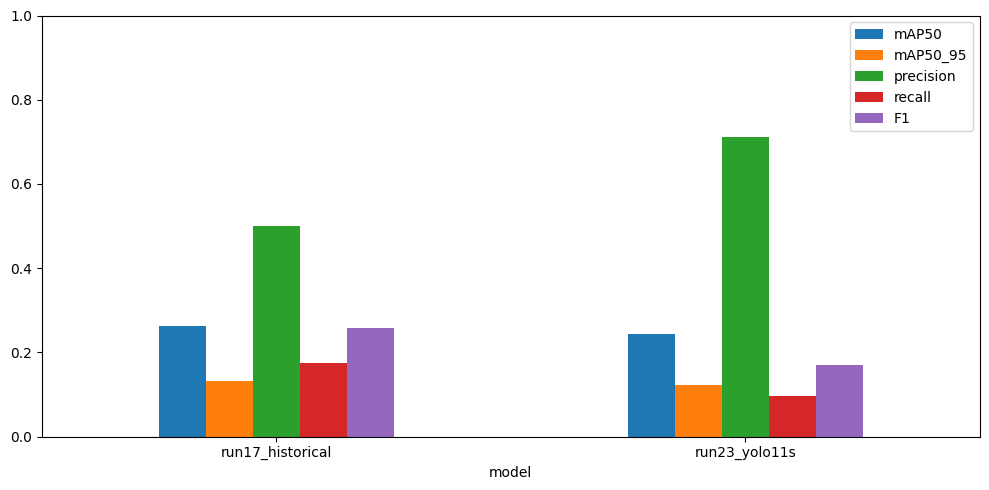

RUN27_LOCAL23_COMPLETE [{"model": "run23_yolo11s", "confidence": 0.001, "mAP50": 0.24283155595723516, "mAP50_95": 0.12250076945092925, "precision": 0.00876361913784936, "recall": 0.4444444444444444, "F1": 0.01718831659020963, "TP": 148, "FP": 16740, "FN": 185, "healthy_images": 56, "healthy_images_with_false_alarm": 56, "healthy_false_boxes": 2015}, {"model": "run23_yolo11s", "confidence": 0.46, "mAP50": 0.24283155595723516, "mAP50_95": 0.12250076945092925, "precision": 0.7111111111111111, "recall": 0.0960960960960961, "F1": 0.16931216931216933, "TP": 32, "FP": 13, "FN": 301, "healthy_images": 56, "healthy_images_with_false_alarm": 1, "healthy_false_boxes": 1}]


In [1]:
from pathlib import Path
from IPython.display import display, Markdown
import json, hashlib, shutil, subprocess, sys
import numpy as np
import pandas as pd
from PIL import Image
import yaml

display(Markdown('## 1. Freeze the Run23 candidate before local scoring\nUse only the YOLO11s candidate selected on China validation. Preserve its frozen confidence, 640-pixel size, NMS IoU 0.7 and max_det 300. Also report the predeclared common confidence 0.46 used for historical Run17. No training, confidence search or model selection on local results. These 190 images have prior project exposure and are not a fresh independent holdout.'))
OUT=Path('/kaggle/working/run27_local23'); OUT.mkdir(exist_ok=True)
INPUT=Path('/kaggle/input')
configs=list(INPUT.glob('**/23-roadscan-yolo-attention-comparison/run23/frozen_model_config.json'))
assert len(configs)==1, configs
cfg=json.loads(configs[0].read_text())
assert cfg['candidate']=='yolo11s_c2psa' and cfg['imgsz']==640 and cfg['confidence']==0.001, cfg
W=configs[0].parent/'selected_best.pt'
sha=hashlib.sha256(W.read_bytes()).hexdigest()
assert sha==cfg['weights_sha256']=='0bf60fce1b5f91afa5878cd4fd8d6e6fbd46eae18ce024f19546782f46d3c6b0'
CLASSES=['D00','D10','D20','D40']; thresholds=[float(cfg['confidence']),0.46]
protocol=dict(candidate=cfg['candidate'],weights_sha256=sha,imgsz=640,nms_iou=0.7,max_det=300,matching_iou=0.5,predeclared_confidences=thresholds,training=False,threshold_search=False,local_prior_exposure=True,annotation='AI-assisted and team-reviewed; not independently audited',automatic_project_replacement=False)
(OUT/'protocol_before_scoring.json').write_text(json.dumps(protocol,indent=2))
display(Markdown('**Frozen checkpoint verified:** Run23 YOLO11s, exact SHA256 matches the selected weights. Confidence 0.001 came from RDD validation, not local labels. A very low confidence can create many false alarms; report it without optimizing on local data.'))

display(Markdown('## 2. Audit the unchanged local dataset\nVerify all 190 images, class order, finite label coordinates and exact duplicate hashes. Keep healthy images with empty labels. No label edits are performed.'))
yamls=list(INPUT.glob('**/roadscan-local-test-v1/**/data.yaml')); assert len(yamls)==1, yamls
src=yamls[0].parent; meta=yaml.safe_load(yamls[0].read_text()); assert meta['names']==CLASSES,meta
images=sorted(p for p in (src/'test/images').glob('*') if p.suffix.lower() in ['.jpg','.jpeg','.png','.webp'])
assert len(images)==190,len(images)
ROOT=Path('/kaggle/working/run27_data')
for f in ['images','labels']: (ROOT/'test'/f).mkdir(parents=True,exist_ok=True)
truth={}; manifest=[]
for ip in images:
    lp=src/'test/labels'/(ip.stem+'.txt'); assert lp.exists(),ip.name
    with Image.open(ip) as im:
        im.load(); w,h=im.size; ph=hashlib.sha256(im.convert('RGB').tobytes()).hexdigest()
    g=[]
    for line in lp.read_text().splitlines():
        if not line.strip(): continue
        v=np.array(list(map(float,line.split()))); assert len(v)==5 and np.isfinite(v).all(),lp
        c,x,y,bw,bh=v; assert c==int(c) and 0<=c<4 and 0<bw<=1 and 0<bh<=1
        assert min(x-bw/2,y-bh/2)>=-0.001 and max(x+bw/2,y+bh/2)<=1.001
        g.append([c,(x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h])
    truth[ip.name]=np.array(g,dtype=float).reshape(-1,5)
    manifest.append(dict(file=ip.name,boxes=len(g),pixel_sha256=ph,label_sha256=hashlib.sha256(lp.read_bytes()).hexdigest()))
    shutil.copy2(ip,ROOT/'test/images'/ip.name); shutil.copy2(lp,ROOT/'test/labels'/lp.name)
manifest=pd.DataFrame(manifest); assert not manifest.pixel_sha256.duplicated().any()
assert manifest.boxes.sum()==333 and (manifest.boxes==0).sum()==56,'Local snapshot changed; review before scoring.'
manifest.to_csv(OUT/'manifest.csv',index=False)
DATA=ROOT/'data.yaml'; DATA.write_text(yaml.safe_dump(dict(path=str(ROOT),train='test/images',val='test/images',test='test/images',names=CLASSES)))
display(Markdown(f'**Audit:** {len(images)} images, {manifest.boxes.sum()} boxes, {(manifest.boxes==0).sum()} healthy images. Loader train/val aliases do not trigger training. Exact duplicate pixels were not found; related views can still affect independence.'))
subprocess.check_call([sys.executable,'-m','pip','install','-q','ultralytics==8.4.177'])
from ultralytics import YOLO
import torch
assert torch.cuda.is_available(),'Enable GPU'
net=YOLO(str(W)); assert [net.names[i] for i in range(4)]==CLASSES,net.names

display(Markdown('## 3. Score the fixed model\nmAP uses confidence 0.001 to retain the ranking. Fixed-confidence precision, recall and F1 use same-class one-to-one IoU 0.5 matching. Record healthy-road false alarms separately. Curves are descriptive only and cannot be used to choose a new local threshold.'))
m=net.val(data=str(DATA),split='test',imgsz=640,batch=8,device=0,workers=2,conf=0.001,iou=0.7,max_det=300,plots=True,project=str(OUT),name='map',exist_ok=True)
maprows=[]
for j,c in enumerate(m.box.ap_class_index):
    maprows.append(dict(cls=CLASSES[int(c)],mAP50=float(m.box.ap50[j]),mAP50_95=float(m.box.ap[j])))
pd.DataFrame(maprows).to_csv(OUT/'per_class_map.csv',index=False)

def overlaps(a,bs):
    inter=np.maximum(np.minimum(a[2:],bs[:,2:])-np.maximum(a[:2],bs[:,:2]),0).prod(1)
    return inter/np.maximum((a[2:]-a[:2]).prod()+(bs[:,2:]-bs[:,:2]).prod(1)-inter,1e-9)
counts={t:np.zeros((4,3),dtype=int) for t in thresholds}; image_rows=[]; predrows=[]
for i,res in enumerate(net.predict(source=str(ROOT/'test/images'),imgsz=640,conf=0.001,iou=0.7,max_det=300,device=0,stream=True,verbose=False)):
    file=Path(res.path).name; g=truth[file]; ps=res.boxes.data.cpu().numpy()
    for pp in ps: predrows.append(dict(file=file,x1=float(pp[0]),y1=float(pp[1]),x2=float(pp[2]),y2=float(pp[3]),confidence=float(pp[4]),cls=CLASSES[int(pp[5])]))
    for t in thresholds:
        pred=ps[ps[:,4]>=t]; ir=dict(file=file,confidence=t,true_boxes=len(g),predicted_boxes=len(pred),healthy=len(g)==0)
        for c in range(4):
            p=pred[pred[:,5]==c]; p=p[np.argsort(-p[:,4],kind='stable')]; gs=g[g[:,0]==c,1:]; used=set(); tp=0
            for pp in p:
                if len(gs):
                    ov=overlaps(pp[:4],gs)
                    for j in used: ov[j]=-1
                    j=int(ov.argmax())
                    if ov[j]>=0.5: used.add(j); tp+=1
            counts[t][c]+=np.array([tp,len(p)-tp,len(gs)-tp])
        image_rows.append(ir)
    if i<12:
        res.boxes=res.boxes[res.boxes.conf>=0.46]
        res.save(filename=str(OUT/f'example_046_{i:03d}.jpg'))
pd.DataFrame(predrows).to_csv(OUT/'predictions.csv',index=False)
ifr=pd.DataFrame(image_rows); ifr.to_csv(OUT/'image_counts.csv',index=False)
perclass=[]; summaries=[]
for t in thresholds:
    for c in range(4):
        tp,fp,fn=map(int,counts[t][c]); p=tp/max(tp+fp,1); r=tp/max(tp+fn,1)
        perclass.append(dict(confidence=t,cls=CLASSES[c],TP=tp,FP=fp,FN=fn,precision=p,recall=r,F1=2*p*r/max(p+r,1e-9)))
    tp,fp,fn=map(int,counts[t].sum(0)); p=tp/max(tp+fp,1); r=tp/max(tp+fn,1)
    healthy=ifr[(ifr.confidence==t)&ifr.healthy]
    row=dict(model='run23_yolo11s',confidence=t,mAP50=float(m.box.map50),mAP50_95=float(m.box.map),precision=p,recall=r,F1=2*p*r/max(p+r,1e-9),TP=tp,FP=fp,FN=fn,healthy_images=len(healthy),healthy_images_with_false_alarm=int((healthy.predicted_boxes>0).sum()),healthy_false_boxes=int(healthy.predicted_boxes.sum()))
    summaries.append(row)
    display(Markdown(f"**Actual local result at {t}:** mAP50={row['mAP50']:.1%}, mAP50-95={row['mAP50_95']:.1%}; precision={p:.1%}, recall={r:.1%}, F1={row['F1']:.1%}; matched={tp}/333, false boxes={fp}, missed={fn}. Healthy images with alarms={row['healthy_images_with_false_alarm']}/56. These results do not change the frozen model or thresholds."))
summary=pd.DataFrame(summaries); pc=pd.DataFrame(perclass)
display(summary); display(pc); display(pd.DataFrame(maprows))
summary.to_csv(OUT/'summary.csv',index=False); pc.to_csv(OUT/'per_class.csv',index=False)
(OUT/'results.json').write_text(json.dumps(dict(protocol=protocol,summary=summaries,per_class=perclass,per_class_map=maprows),indent=2))
comparison=pd.DataFrame([dict(model='run17_historical',mAP50=0.2624511953497888,mAP50_95=0.13148693083466007,precision=0.5,recall=0.17417417417417416,F1=0.2583518930957684),{k:v for k,v in summaries[1].items() if k in ['model','mAP50','mAP50_95','precision','recall','F1']}])
display(Markdown('## 4. Descriptive comparison with the historical Run17 score\nBoth rows use confidence 0.46, 640 pixels and the same local snapshot. The historical reference is recorded from Run22, not retrained here. This is a post-exposure comparison, not a new independent model-selection test. No automatic replacement of Run17.'))
display(comparison); comparison.to_csv(OUT/'historical_comparison_046.csv',index=False)
import matplotlib.pyplot as plt
comparison.set_index('model')[['mAP50','mAP50_95','precision','recall','F1']].plot.bar(ylim=(0,1),rot=0,figsize=(10,5)); plt.tight_layout(); plt.savefig(OUT/'comparison_046.png'); plt.show()
(OUT/'README_RESULTS.md').write_text('# Run23 local evaluation\n\n'+summary.to_markdown(index=False)+'\n\n'+pc.to_markdown(index=False)+'\n\nNo training or local threshold search. Prior exposure, AI-assisted label quality and related scene views limit independence. Original Run22 results and local labels unchanged. No automatic project model replacement.')
shutil.make_archive('/kaggle/working/run27_local23_results','zip',OUT)
print('RUN27_LOCAL23_COMPLETE',json.dumps(summaries),flush=True)


In [2]:
# Evaluation and interpretation are contained in the preceding cell. No diagnostic tuning.

In [3]:
# Preserve local labels and historical results without modification.